# Resultados Kaggle — Semana 10, 60 épocas completas

Este notebook es el **informe reproducible del experimento final**. El entrenamiento y la inferencia pesada se ejecutaron en kernels privados de Kaggle; aquí se leen los artefactos descargados y se muestran sus resultados sin volver a entrenar.

- Entrenamiento: 60 épocas obligatorias, sin early stopping y sin EMA.
- Inicialización: backbone, CBAM y detector del checkpoint físico 2.5D de Semana 9.
- Selección final: solo validación volumétrica; test se consultó una única vez después de congelar el modelo.
- Extensión del taller: HD95 y ASSD 3D por fragmento.

## 1. Configuración y localización de artefactos

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

def encontrar_raiz(inicio: Path) -> Path:
    for candidato in (inicio, *inicio.parents):
        if (candidato / 'outputs' / 'kaggle' / 's10_60ep').exists():
            return candidato
    raise FileNotFoundError('No se encontró la raíz con los resultados de Kaggle.')

ROOT = encontrar_raiz(Path.cwd().resolve())
TRAIN_DIR = ROOT / 'outputs' / 'kaggle' / 's10_60ep'
FINAL_DIR = ROOT / 'outputs' / 'kaggle' / 's10_60ep_puntos_5_a_9'
HISTORIAL = TRAIN_DIR / 's10_kaggle_60ep_sin_early_stopping_historial.json'
MODELO_FINAL = FINAL_DIR / 'modelo_final_semana10.pth'

print('Raíz:', ROOT)
print('Entrenamiento:', TRAIN_DIR)
print('Evaluación final:', FINAL_DIR)
print('Modelo final:', MODELO_FINAL)

Raíz: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main
Entrenamiento: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\kaggle\s10_60ep
Evaluación final: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\kaggle\s10_60ep_puntos_5_a_9
Modelo final: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\kaggle\s10_60ep_puntos_5_a_9\modelo_final_semana10.pth


## 2. Verificación de Semana 9 y del entrenamiento limpio

In [2]:
historial = json.loads(HISTORIAL.read_text(encoding='utf-8'))
args = historial['args']
verificacion = {
    'épocas solicitadas': args['epochs'],
    'épocas completadas': historial['epochs_completed'],
    'parada temprana': historial['stopped_early'],
    'motivo de parada': historial['stop_reason'],
    'EMA': args['ema'],
    'checkpoint Semana 9': Path(args['week9_checkpoint']).name,
    'freeze Semana 9 (épocas)': args['freeze_week9_epochs'],
    'entrada 2.5D (contexto)': args['context'],
    'rotación máxima': args['aug_rot_deg'],
    'rotación en milímetros': args['aug_mm'],
    'cuDNN desactivado': args['disable_cudnn'],
    'duración (min)': round(historial['minutes'], 2),
}
display(pd.Series(verificacion, name='valor').to_frame())
assert historial['epochs_completed'] == 60
assert historial['stopped_early'] is False and historial['stop_reason'] is None
assert args['ema'] == 0.0 and args['aug_mm'] is True
print('OK: corrida limpia de 60 épocas, sin EMA y sin early stopping.')

,valor
épocas solicitadas,60
épocas completadas,60
parada temprana,False
motivo de parada,None
EMA,0.0
checkpoint Semana 9,week9_25d_rotacion_fisica_desde_cero_w32_e35_s...
freeze Semana 9 (épocas),5
entrada 2.5D (contexto),1
rotación máxima,35.0
rotación en milímetros,True


OK: corrida limpia de 60 épocas, sin EMA y sin early stopping.


## 3. Entrenamiento: pérdida y métricas de validación

,loss,classification_f1_macro,detection_map50,segmentation_dice_macro,instance_dice_matched
epoch,,,,,
1,2.3712,0.9122,0.4993,0.7946,0.6845
5,1.1991,0.9018,0.7170,0.8696,0.7561
10,0.9450,0.9560,0.7124,0.9167,0.7786
15,0.8454,0.9562,0.8703,0.9456,0.8081
20,0.7989,0.9706,0.8847,0.9559,0.8360
25,0.7337,0.9714,0.8932,0.9553,0.8377
30,0.7024,0.9533,0.9097,0.9551,0.8365
35,0.6766,0.9783,0.9235,0.9595,0.8471
40,0.6475,0.9764,0.9535,0.9668,0.8567


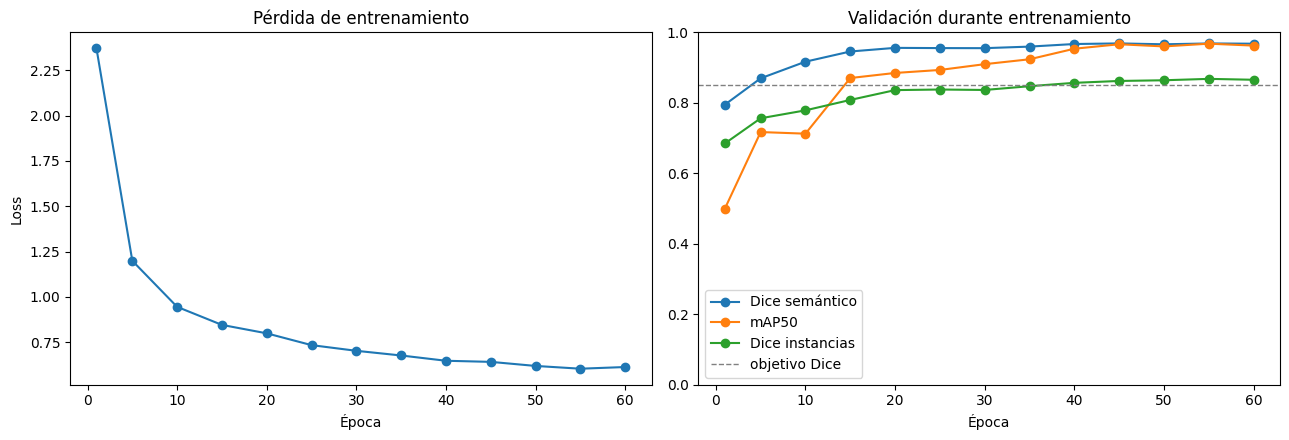

Mejor Dice de instancias: 0.8680 (época 55)
Época 60: loss=0.6130, Dice semántico=0.9677, mAP50=0.9624, Dice instancias=0.8654


In [3]:
df_hist = pd.DataFrame(historial['history'])
columnas = ['epoch', 'loss', 'classification_f1_macro', 'detection_map50',
            'segmentation_dice_macro', 'instance_dice_matched']
display(df_hist[columnas].round(4).set_index('epoch'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(df_hist.epoch, df_hist.loss, marker='o')
axes[0].set(title='Pérdida de entrenamiento', xlabel='Época', ylabel='Loss')
for clave, etiqueta in [
    ('segmentation_dice_macro', 'Dice semántico'),
    ('detection_map50', 'mAP50'),
    ('instance_dice_matched', 'Dice instancias'),
]:
    axes[1].plot(df_hist.epoch, df_hist[clave], marker='o', label=etiqueta)
axes[1].axhline(0.85, color='gray', linestyle='--', linewidth=1, label='objetivo Dice')
axes[1].set(title='Validación durante entrenamiento', xlabel='Época', ylim=(0, 1))
axes[1].legend()
plt.tight_layout()
plt.show()

mejor_inst = df_hist.loc[df_hist.instance_dice_matched.idxmax()]
ultima = df_hist.iloc[-1]
print(f"Mejor Dice de instancias: {mejor_inst.instance_dice_matched:.4f} (época {int(mejor_inst.epoch)})")
print(f"Época 60: loss={ultima.loss:.4f}, Dice semántico={ultima.segmentation_dice_macro:.4f}, "
      f"mAP50={ultima.detection_map50:.4f}, Dice instancias={ultima.instance_dice_matched:.4f}")

## 4. Comparación de checkpoints y selección final

In [4]:
manifiesto = json.loads((FINAL_DIR / 'modelo_final_semana10.json').read_text(encoding='utf-8'))
comparacion = []
for etiqueta, archivo in [
    ('mejor durante entrenamiento', 'candidato_best_val.json'),
    ('época 60', 'candidato_epoch60_val.json'),
]:
    datos = json.loads((FINAL_DIR / archivo).read_text(encoding='utf-8'))
    m = datos['subsets']['todo']
    comparacion.append({
        'candidato': etiqueta,
        'F1 clasificación': m['classification_f1_macro'],
        'mAP50': m['detection_map50'],
        'Dice semántico': m['segmentation_dice_macro'],
        'Dice instancias': m['instance_dice_matched'],
    })
display(pd.DataFrame(comparacion).set_index('candidato').round(4))
print('Seleccionado:', manifiesto['checkpoint_seleccionado'])
print('Criterio:', manifiesto['criterio_seleccion'])
print('La época 60 ganó por una diferencia de',
      f"{manifiesto['candidatos_validacion'][manifiesto['checkpoint_seleccionado']] - min(manifiesto['candidatos_validacion'].values()):.4f}",
      'en Dice de instancias volumétrico.')

,F1 clasificación,mAP50,Dice semántico,Dice instancias
candidato,,,,
mejor durante entrenamiento,0.9766,0.9686,0.9699,0.8696
época 60,0.9721,0.9673,0.9697,0.8707


Seleccionado: s10_kaggle_60ep_sin_early_stopping_epoch60.pth
Criterio: instance_dice_matched de validación volumétrica (subconjunto todo)
La época 60 ganó por una diferencia de 0.0011 en Dice de instancias volumétrico.


## 5. Trazabilidad e integridad del modelo publicado

In [5]:
sha_local = hashlib.sha256(MODELO_FINAL.read_bytes()).hexdigest()
integridad = {
    'archivo': MODELO_FINAL.name,
    'tamaño (bytes)': MODELO_FINAL.stat().st_size,
    'SHA-256 manifiesto': manifiesto['sha256'],
    'SHA-256 local': sha_local,
    'coincide': sha_local == manifiesto['sha256'],
}
display(pd.Series(integridad, name='valor').to_frame())
assert integridad['coincide']
print('OK: el modelo descargado es exactamente el publicado por Kaggle.')

,valor
archivo,modelo_final_semana10.pth
tamaño (bytes),11011469
SHA-256 manifiesto,04499d26562696fe70c76b1d81748dc57e8236687998de...
SHA-256 local,04499d26562696fe70c76b1d81748dc57e8236687998de...
coincide,True


OK: el modelo descargado es exactamente el publicado por Kaggle.


## 6. Evaluación volumétrica final: validación y test

conjunto,test,validación
métrica,,
classification_auc_macro,0.9961,0.9983
classification_f1_macro,0.9737,0.9721
detection_iou_mean,0.9467,0.9458
detection_map50,0.9686,0.9673
detection_map50_95,0.9130,0.9014
instance_dice_matched,0.8798,0.8707
instance_iou_matched,0.8207,0.8096
segmentation_dice_macro,0.9707,0.9697
segmentation_iou_macro,0.9431,0.9414


conjunto,test,validación
métrica,,
classification_auc_macro,True,True
classification_f1_macro,True,True
detection_iou_mean,True,True
detection_map50,True,True
detection_map50_95,True,True
instance_dice_matched,True,True
instance_iou_matched,True,True
segmentation_dice_macro,True,True
segmentation_iou_macro,True,True


Validación: 9 / 9 métricas
Test: 9 / 9 métricas


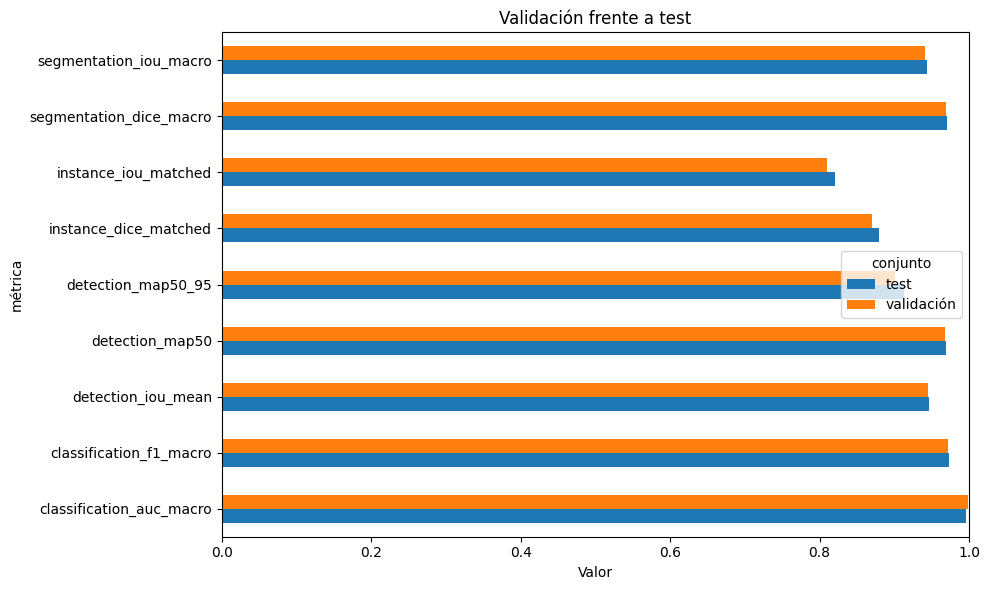

In [6]:
validacion = json.loads((FINAL_DIR / 'modelo_final_semana10_val.json').read_text(encoding='utf-8'))
prueba = json.loads((FINAL_DIR / 'modelo_final_semana10_test.json').read_text(encoding='utf-8'))
objetivos = {
    'classification_f1_macro': 0.85,
    'classification_auc_macro': 0.85,
    'detection_iou_mean': 0.65,
    'detection_map50': 0.65,
    'detection_map50_95': 0.40,
    'segmentation_dice_macro': 0.85,
    'segmentation_iou_macro': 0.70,
    'instance_dice_matched': 0.85,
    'instance_iou_matched': 0.70,
}
filas = []
for conjunto, datos in [('validación', validacion), ('test', prueba)]:
    resumen = datos['subsets']['todo']
    for metrica, objetivo in objetivos.items():
        valor = float(resumen[metrica])
        filas.append({'conjunto': conjunto, 'métrica': metrica, 'valor': valor,
                      'objetivo': objetivo, 'cumple': valor >= objetivo})
tabla_metricas = pd.DataFrame(filas)
display(tabla_metricas.pivot(index='métrica', columns='conjunto', values='valor').round(4))
display(tabla_metricas.pivot(index='métrica', columns='conjunto', values='cumple'))
print('Validación:', int(tabla_metricas.query("conjunto == 'validación'").cumple.sum()), '/ 9 métricas')
print('Test:', int(tabla_metricas.query("conjunto == 'test'").cumple.sum()), '/ 9 métricas')

grafica = tabla_metricas.pivot(index='métrica', columns='conjunto', values='valor')
ax = grafica.plot(kind='barh', figsize=(10, 6), xlim=(0, 1), title='Validación frente a test')
ax.set_xlabel('Valor')
plt.tight_layout()
plt.show()

### Lectura de test

El resultado de test es la medición principal ante pacientes no vistos. La configuración fue congelada usando validación antes de consultar test. La similitud entre ambos conjuntos y el hecho de que test no sea peor de manera sistemática no muestran señales de sobreajuste relevante.

## Auditoría de orientación y rotación física

In [7]:
rot_dir = FINAL_DIR / 'auditoria_rotacion_fisica'
filas_rotacion = []
for path in sorted(rot_dir.glob('*.json')):
    datos = json.loads(path.read_text(encoding='utf-8'))
    m = datos['subsets']['todo']
    filas_rotacion.append({
        'experimento': path.stem,
        'correcciones aceptadas': sum(bool(v.get('accepted')) for v in datos.get('normalization', {}).values()),
        'F1 clasificación': m['classification_f1_macro'],
        'mAP50': m['detection_map50'],
        'Dice semántico': m['segmentation_dice_macro'],
        'Dice instancias': m['instance_dice_matched'],
    })
tabla_rotacion = pd.DataFrame(filas_rotacion).set_index('experimento')
display(tabla_rotacion.round(4))

for grados in (30, 60):
    sin = tabla_rotacion.loc[f'rotmm{grados}_sin_corregir']
    con = tabla_rotacion.loc[f'rotmm{grados}_corregido']
    print(f"{grados}° — cambio al normalizar: mAP50 {con['mAP50']-sin['mAP50']:+.4f}, "
          f"Dice semántico {con['Dice semántico']-sin['Dice semántico']:+.4f}, "
          f"Dice instancias {con['Dice instancias']-sin['Dice instancias']:+.4f}")

,correcciones aceptadas,F1 clasificación,mAP50,Dice semántico,Dice instancias
experimento,,,,,
limpio_normalizado,0,0.9721,0.9673,0.9697,0.8707
rotmm30_corregido,13,0.9750,0.9596,0.9595,0.8542
rotmm30_sin_corregir,0,0.9680,0.9480,0.9596,0.8570
rotmm60_corregido,11,0.9457,0.8567,0.8772,0.7807
rotmm60_sin_corregir,0,0.8729,0.3883,0.7164,0.6025


30° — cambio al normalizar: mAP50 +0.0115, Dice semántico -0.0001, Dice instancias -0.0028
60° — cambio al normalizar: mAP50 +0.4684, Dice semántico +0.1608, Dice instancias +0.1782


La normalización es especialmente útil en el estrés de **60°**: recupera gran parte de detección y segmentación. En **30°**, el aumento físico de entrenamiento ya aporta robustez y la corrección no mejora todas las métricas; por eso el algoritmo conserva controles de confianza y no debe presentarse como una garantía universal.

## 7. Publicación del modelo final

In [8]:
publicacion = {
    'modelo final': MODELO_FINAL,
    'checkpoint seleccionado': manifiesto['checkpoint_seleccionado'],
    'evaluación de validación': FINAL_DIR / manifiesto['evaluacion_validacion'],
    'evaluación de test': FINAL_DIR / manifiesto['evaluacion_prueba'],
    'SHA-256': manifiesto['sha256'],
}
display(pd.Series({k: str(v) for k, v in publicacion.items()}, name='valor').to_frame())

,valor
modelo final,E:\Proyecto_2_Analytics\proyecto2-analitica-da...
checkpoint seleccionado,s10_kaggle_60ep_sin_early_stopping_epoch60.pth
evaluación de validación,E:\Proyecto_2_Analytics\proyecto2-analitica-da...
evaluación de test,E:\Proyecto_2_Analytics\proyecto2-analitica-da...
SHA-256,04499d26562696fe70c76b1d81748dc57e8236687998de...


## 8. Aportación final de CBAM por cabeza

In [9]:
cbam = json.loads((FINAL_DIR / 'modelo_final_semana10_cbam_aportacion.json').read_text(encoding='utf-8'))
filas_cbam = []
for etiqueta, clave in [('clasificación', 'clasificacion'), ('detección', 'deteccion'),
                        ('segmentación', 'segmentacion'), ('score general', 'general')]:
    filas_cbam.append({
        'cabeza': etiqueta,
        'con CBAM': cbam['con_cbam'][clave],
        'sin CBAM': cbam['sin_cbam'][clave],
        'aportación': cbam['aportacion'][clave],
    })
display(pd.DataFrame(filas_cbam).set_index('cabeza').round(4))
print(f"Caída general al retirar CBAM: {cbam['caida_al_retirar_cbam_pct']:.1f}%")
print('Nota metodológica:', cbam['advertencia'])

,con CBAM,sin CBAM,aportación
cabeza,,,
clasificación,0.9721,0.8842,0.0880
detección,0.8490,0.2366,0.6124
segmentación,0.9202,0.6954,0.2248
score general,0.9138,0.6054,0.3084


Caída general al retirar CBAM: 33.8%
Nota metodológica: Mide dependencia en inferencia, no ganancia causal de entrenamiento.


## 9. Extensión opcional: HD95 y ASSD 3D por fragmento

In [10]:
superficies = {}
filas_superficie = []
for split in ('val', 'test'):
    path = FINAL_DIR / f'modelo_final_semana10_hd95_assd_{split}.json'
    datos = json.loads(path.read_text(encoding='utf-8'))
    superficies[split] = datos
    resumen = datos['resumen']
    for tipo, grupo in [('todos', resumen), *resumen['por_tipo'].items()]:
        cobertura = grupo['cobertura_fragmentos'] if tipo == 'todos' else grupo['cobertura']
        n_gt = grupo['n_fragmentos_gt'] if tipo == 'todos' else grupo['n_gt']
        filas_superficie.append({
            'conjunto': split,
            'tipo': tipo,
            'fragmentos GT': n_gt,
            'cobertura': cobertura,
            'ASSD media (mm)': grupo['assd_mm'].get('media', np.nan),
            'ASSD mediana (mm)': grupo['assd_mm'].get('mediana', np.nan),
            'HD95 media (mm)': grupo['hd95_mm'].get('media', np.nan),
            'HD95 mediana (mm)': grupo['hd95_mm'].get('mediana', np.nan),
        })
tabla_superficie = pd.DataFrame(filas_superficie).set_index(['conjunto', 'tipo'])
display(tabla_superficie.round(3))
print('Menor ASSD/HD95 es mejor. Las distancias se resumen solo para fragmentos detectados;')
print('la cobertura declara explícitamente los fragmentos omitidos.')

fragmentos GT  cobertura  ASSD media (mm)  \
conjunto tipo                                                    
val      todos                  86      0.965            2.681   
         principal              45      1.000            1.195   
         secundario             41      0.927            4.440   
test     todos                  86      0.953            1.472   
         principal              45      1.000            1.039   
         secundario             41      0.902            1.999   

                     ASSD mediana (mm)  HD95 media (mm)  HD95 mediana (mm)  
conjunto tipo                                                               
val      todos                   0.849           13.487              3.691  
         principal               0.480            7.535              2.260  
         secundario              1.611           20.536              8.188  
test     todos                   0.725            7.738              2.546  
         principal               0.611            5.439              1.657  
         secundario              1.149           10.534              4.898

Menor ASSD/HD95 es mejor. Las distancias se resumen solo para fragmentos detectados;
la cobertura declara explícitamente los fragmentos omitidos.


In [11]:
for split, datos in superficies.items():
    filas = []
    for caso in datos['por_caso']:
        filas.append({
            'caso': caso['case_id'],
            'cobertura': caso['cobertura_fragmentos'],
            'ASSD media (mm)': caso['assd_mm'].get('media', np.nan),
            'HD95 media (mm)': caso['hd95_mm'].get('media', np.nan),
        })
    detalle = pd.DataFrame(filas).sort_values('HD95 media (mm)', ascending=False)
    print(f'Casos de {split}, ordenados por HD95 medio:')
    display(detalle.round(3).reset_index(drop=True))

Casos de val, ordenados por HD95 medio:


,caso,cobertura,ASSD media (mm),HD95 media (mm)
0,014,0.857,7.302,34.040
1,087,1.000,6.191,27.261
2,027,1.000,3.179,20.184
3,078,1.000,4.967,19.122
4,077,1.000,3.207,17.937
5,095,1.000,1.997,14.924
6,050,1.000,1.773,14.702
7,024,0.889,2.279,10.216
8,060,0.833,1.362,8.435
9,057,1.000,1.458,8.143


Casos de test, ordenados por HD95 medio:


,caso,cobertura,ASSD media (mm),HD95 media (mm)
0,039,0.778,3.357,20.104
1,061,1.000,3.825,18.759
2,012,1.000,1.619,12.699
3,065,1.000,1.893,11.825
4,098,1.000,1.466,8.637
5,007,0.857,1.991,8.110
6,086,1.000,1.149,6.372
7,047,1.000,1.021,5.356
8,054,0.857,1.027,5.000
9,089,1.000,1.073,3.567


## Conclusión final

- El experimento ejecutó **60 épocas completas**, sin parada temprana, sin EMA y sin valores no finitos.
- El checkpoint final seleccionado fue **s10_kaggle_60ep_sin_early_stopping_epoch60.pth**, escogido únicamente con validación volumétrica.
- Test cumple **9/9 métricas mínimas**: Dice semántico `0.9707` y Dice de instancias `0.8798`.
- La ablación de inferencia muestra una caída general de `33.8%` al retirar CBAM. Esto mide dependencia del checkpoint; no sustituye entrenar un control independiente sin CBAM.
- En test, la cobertura de fragmentos para HD95/ASSD es `95.3%`, con ASSD medio `1.472 mm` y HD95 medio `7.738 mm`.
- La principal limitación sigue estando en fragmentos secundarios y en giros extremos: la corrección de 60° mejora mucho el resultado, pero el Dice de instancias queda por debajo del objetivo de 0.85.

**Estado:** experimento completo hasta el punto 9, modelo final publicado y artefactos descargados.

## Evidencia original

- Kernel de entrenamiento: `federicog19/pengwin-s10-60ep-sin-early-stop`
- Kernel de evaluación: `federicog19/pengwin-s10-60ep-puntos-5-a-9`
- Los JSON y CSV originales permanecen en `outputs/kaggle/`; este notebook solo los resume y visualiza.